In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

project_path = "/content/drive/MyDrive/Neural_Network"
os.chdir(project_path)

In [12]:
!ls

checkpoints  data	 model.py  README.md
config.py    dataset.py  notebook  train.py


In [13]:
import torch
import torch.nn as nn

from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader

from torch import GradScaler
from torch import autocast
from torch.optim import AdamW
from torch.nn.utils import clip_grad_norm_
from torch.optim.lr_scheduler import CosineAnnealingLR

In [14]:
class config():
  batch_size=64
  lr_rate=3e-5
  weight_decay=1e-4
  device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
  seed=42
  epochs=3
  num_classes=10
  grad_clip=1.0
  image_size=224
  num_workers=4

cf=config()

In [15]:
train_transforms= transforms.Compose([
  transforms.Resize((cf.image_size, cf.image_size)),
  transforms.RandomHorizontalFlip(),
  transforms.RandomCrop(cf.image_size, padding=4),
  transforms.ToTensor(),
  transforms.Normalize(
    mean=[0.4914, 0.4822, 0.4465],
    std=[0.2470, 0.2435, 0.2616]
  )
])

test_transforms= transforms.Compose([
  transforms.Resize((cf.image_size, cf.image_size)),
  transforms.ToTensor(),
  transforms.Normalize(
    mean=[0.4914, 0.4822, 0.4465],
    std=[0.2470, 0.2435, 0.2616]
  )
])

In [16]:
def get_dataloaders(batch_size, train_transforms, test_transforms):
  train_datasets= datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transforms
  )
  test_datasets=datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=test_transforms
  )

  train_loader= DataLoader(
    train_datasets,
    batch_size=cf.batch_size,
    shuffle=True,
    num_workers= cf.num_workers,
    pin_memory=True,
    persistent_workers= (cf.num_workers>0),
    prefetch_factor=2 if cf.num_workers>0 else None
  )

  test_loader=DataLoader(
    test_datasets,
    batch_size=cf.batch_size,
    num_workers= cf.num_workers,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2
  )

  return train_loader, test_loader


In [17]:
class VGGClassifier(nn.Module):
  def __init__(self):
    super().__init__()

    self.block1= nn.Sequential(
      nn.Conv2d(3, 64, 3, padding=1),
      nn.BatchNorm2d(64),
      nn.ReLU(),


      nn.Conv2d(64, 64, 3, padding=1),
      nn.BatchNorm2d(64),
      nn.ReLU(),

      nn.MaxPool2d(2)
    )

    self.block2= nn.Sequential(
      nn.Conv2d(64, 128, 3, padding=1),
      nn.BatchNorm2d(128),
      nn.ReLU(),

      nn.Conv2d(128, 128, 3, padding=1),
      nn.BatchNorm2d(128),
      nn.ReLU(),

      nn.MaxPool2d(2)
    )

    self.block3=nn.Sequential(
      nn.Conv2d(128, 256, 3, padding=1),
      nn.BatchNorm2d(256),
      nn.ReLU(),

      nn.Conv2d(256, 256, 3, padding=1),
      nn.BatchNorm2d(256),
      nn.ReLU(),

      nn.Conv2d(256, 256, 3, padding=1),
      nn.BatchNorm2d(256),
      nn.ReLU(),

    )

    self.block4=nn.Sequential(
      nn.Conv2d(256, 512, 3, padding=1),
      nn.BatchNorm2d(512),
      nn.ReLU(),

      nn.Conv2d(512, 512, 3, padding=1),
      nn.BatchNorm2d(512),
      nn.ReLU(),

      nn.Conv2d(512, 512, 3, padding=1),
      nn.BatchNorm2d(512),
      nn.ReLU(),

      nn.MaxPool2d(2)
    )

    self.block5=nn.Sequential(
      nn.Conv2d(512,512, 3, padding=1),
      nn.BatchNorm2d(512),
      nn.ReLU(),

      nn.Conv2d(512, 512, 3, padding=1),
      nn.BatchNorm2d(512),
      nn.ReLU(),

      nn.Conv2d(512, 512, 3, padding=1),
      nn.BatchNorm2d(512),
      nn.ReLU(),

      nn.MaxPool2d(2)
    )

    self.classifier=nn.Sequential(
      nn.AdaptiveAvgPool2d(output_size=(1,1)),
      nn.Flatten(),

      nn.Linear(512, 256),
      nn.BatchNorm1d(256),
      nn.ReLU(),
      nn.Dropout(0.2),

      nn.Linear(256, 10)
    )

  def forward(self, x):
      x= self.block1(x)
      x= self.block2(x)
      x= self.block3(x)
      x= self.block4(x)
      x= self.block5(x)

      x= self.classifier(x)

      return x



In [18]:
model= VGGClassifier()

In [19]:
train_loader, test_loader= get_dataloaders(cf.batch_size, train_transforms, test_transforms)

optimizer=AdamW(
  model.parameters(),
  lr=cf.lr_rate,
  weight_decay=cf.weight_decay
)
scheduler=CosineAnnealingLR(
  optimizer,
  T_max=cf.epochs
)

criterion=nn.CrossEntropyLoss()
scaler= GradScaler()


100%|██████████| 170M/170M [25:41<00:00, 111kB/s]
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [20]:
def validation(model, test_loader):
  model.eval()
  val_loss=0.0
  correct=0
  total=0

  with torch.no_grad():
    for batch_idx, (features, labels) in enumerate(test_loader):
      features=features.to(cf.device)
      labels=labels.to(cf.device)

      use_amp = torch.cuda.is_available() and cf.device.type == "cuda"
      with autocast(device_type="cuda",
                    dtype=torch.float16,
                    enabled=use_amp):
        logits=model(features)
        loss=criterion(logits, labels)

      val_loss+=loss.item()
      pred=logits.argmax(dim=1)
      correct+=(pred==labels).sum().item()
      total+=labels.size(0)
    val_acc=correct/total
    val_loss /= len(test_loader)
    return val_loss, val_acc

In [21]:
from tqdm.auto import tqdm

train_losses = []
val_losses = []
val_accuracies = []
lrs = []

def train_model(model):
    best_acc = 0.0
    patience = 3
    counter = 0

    model.to(cf.device)

    for epoch in range(cf.epochs):

        model.train()

        running_loss = 0.0
        running_correct = 0
        running_total = 0

        pbar = tqdm(
            enumerate(train_loader),
            total=len(train_loader),
            desc=f"Epoch {epoch+1}/{cf.epochs}"
        )

        for batch_idx, (features, labels) in pbar:

            features = features.to(cf.device)
            labels = labels.to(cf.device)

            optimizer.zero_grad(set_to_none=True)

            use_amp = (
                torch.cuda.is_available()
                and cf.device.type == "cuda"
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=use_amp
            ):
                logits = model(features)
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                cf.grad_clip
            )

            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item()

            preds = logits.argmax(dim=1)

            running_correct += (preds == labels).sum().item()
            running_total += labels.size(0)

            batch_acc = (preds == labels).float().mean().item()

            pbar.set_postfix({
                "batch": f"{batch_idx+1}/{len(train_loader)}",
                "loss": f"{loss.item():.4f}",
                "acc": f"{batch_acc*100:.2f}%"
            })

        epoch_loss = running_loss / len(train_loader)
        epoch_acc = running_correct / running_total

        train_losses.append(epoch_loss)

        val_loss, val_acc = validation(model, test_loader)

        val_losses.append(val_loss)
        val_accuracies.append(val_acc)

        scheduler.step()
        lrs.append(optimizer.param_groups[0]["lr"])

        if val_acc > best_acc:
            best_acc = val_acc
            counter = 0

            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "best_acc": best_acc
            }, "best_model.pth")

        else:
            counter += 1

        print(
            f"\nEpoch [{epoch+1}/{cf.epochs}] Summary\n"
            f"Train Loss: {epoch_loss:.4f} | "
            f"Train Acc: {epoch_acc*100:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc*100:.2f}% | "
            f"Best Acc: {best_acc*100:.2f}%"
        )

        if counter >= patience:
            print(f"\nEarly stopping at epoch {epoch+1}")
            break


In [22]:
train_model(model)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch 1/3:   0%|          | 0/782 [00:00<?, ?it/s]


Epoch [1/3] Summary
Train Loss: 1.4279 | Train Acc: 49.18% | Val Loss: 1.4308 | Val Acc: 51.80% | Best Acc: 51.80%


Epoch 2/3:   0%|          | 0/782 [00:00<?, ?it/s]


Epoch [2/3] Summary
Train Loss: 1.0030 | Train Acc: 65.90% | Val Loss: 1.0407 | Val Acc: 64.63% | Best Acc: 64.63%


Epoch 3/3:   0%|          | 0/782 [00:00<?, ?it/s]


Epoch [3/3] Summary
Train Loss: 0.7838 | Train Acc: 74.55% | Val Loss: 0.8007 | Val Acc: 72.91% | Best Acc: 72.91%


In [23]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

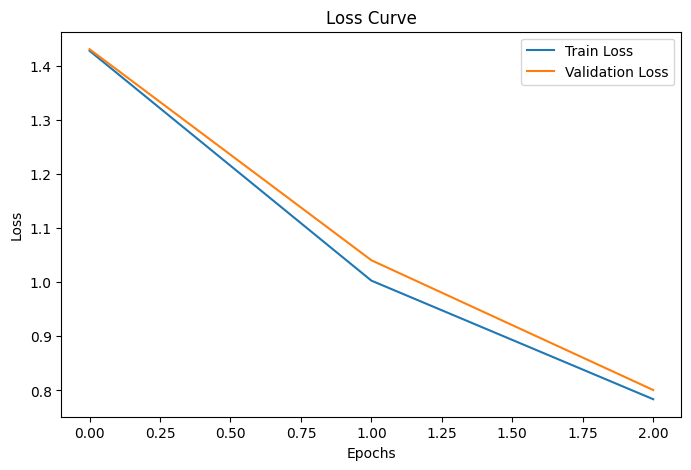

In [24]:
plt.figure(figsize=(8,5))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.title("Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

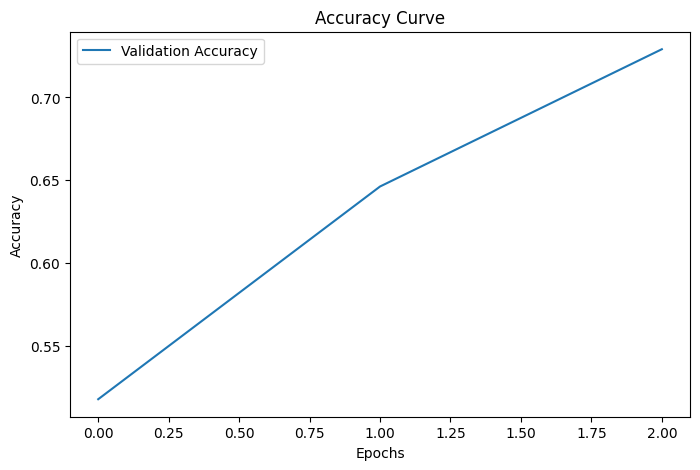

In [25]:
plt.figure(figsize=(8,5))

plt.plot(val_accuracies, label="Validation Accuracy")

plt.title("Accuracy Curve")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

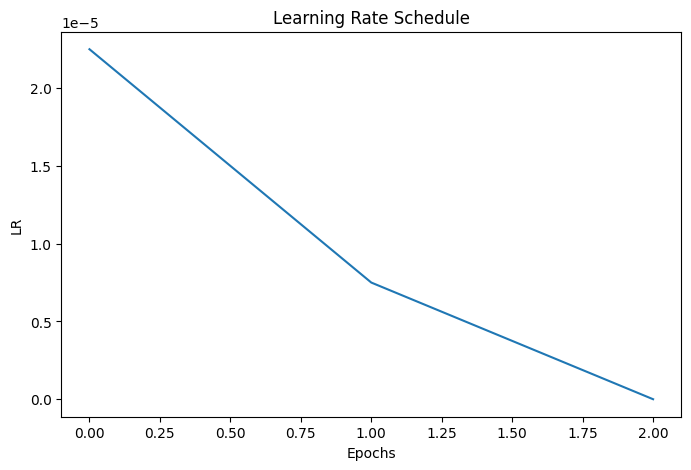

In [26]:
plt.figure(figsize=(8,5))

plt.plot(lrs)

plt.title("Learning Rate Schedule")
plt.xlabel("Epochs")
plt.ylabel("LR")
plt.show()

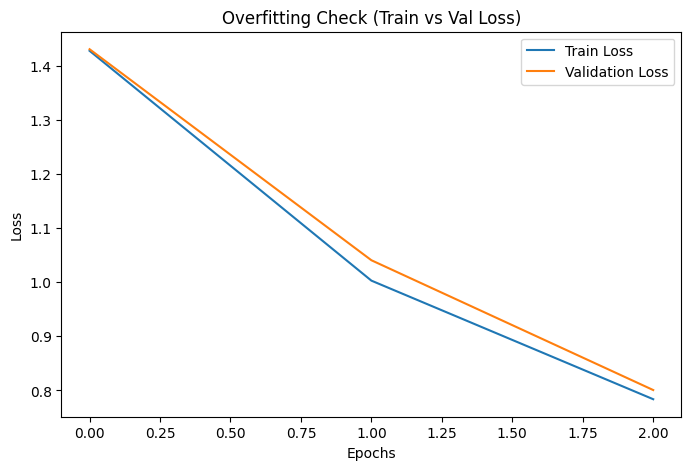

In [27]:
plt.figure(figsize=(8,5))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.title("Overfitting Check (Train vs Val Loss)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [29]:
def plot_confusion_matrix(model, test_loader):
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for features, labels in test_loader:
            features = features.to(cf.device)

            outputs = model(features)
            preds = outputs.argmax(dim=1)

            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.numpy())

    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    cm = confusion_matrix(all_labels, all_preds)

    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

    plt.title("Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

In [30]:
import torch
from torchvision import transforms
from PIL import Image


classes = [
    "airplane", "automobile", "bird", "cat",
    "deer", "dog", "frog", "horse",
    "ship", "truck"
]

infer_transform = transforms.Compose([
    transforms.Resize((cf.image_size, cf.image_size)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.4914, 0.4822, 0.4465],
        std=[0.2470, 0.2435, 0.2616]
    )
])

def predict_image(model, image_path, device):
    # load model weights
    checkpoint = torch.load("best_model.pth", map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(device)
    model.eval()

    image = Image.open(image_path).convert("RGB")
    image = infer_transform(image)
    image = image.unsqueeze(0).to(device)  # add batch dim

    with torch.no_grad():
        logits = model(image)
        probs = torch.softmax(logits, dim=1)
        pred_class = torch.argmax(probs, dim=1).item()
        confidence = probs[0, pred_class].item()

    return classes[pred_class], confidence

In [31]:
predict_image(model,"Alone_boat_on_water_surface.jpg" , cf.device)

FileNotFoundError: [Errno 2] No such file or directory: 'Alone_boat_on_water_surface.jpg'